# Classification using confidence

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/classification_using_confidence/classification_using_confidence.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/classification_using_confidence/classification_using_confidence.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/classification_using_confidence).

Every company that files an annual report with the SEC describes its own business in it. We
classify those descriptions under the Standard Industrial Classification: 75 industry
groups, one `Choice` question per document.

Many filings are easy. A regional bank is a regional bank. Some are not: a company that
just sold one of its two segments, or a startup describing a business it plans to enter
rather than one it runs. The model has to pick a group regardless, and the answer for a
hard case looks no different from the answer for an easy one. Telling hard cases from easy
ones is normally where the cost goes: a second model, extra calls, human review.

A Choice already tells you. Alongside the winning option it returns `confidence`, high when
nearly all the probability landed on one option and low when it spread across several. That
one number separates the answers you can trust from the ones you can't.

What to do with an untrusted answer depends on your labels. SIC labels form a hierarchy:
industry groups roll up into broader divisions. When the model is unsure of the group,
report the division it belongs to. The division follows from the group, so there is no
second call.

Across 60 filings, a confidence cutoff of 0.9 marks 28 as confident and 32 as not. The
confident 28 are right 93% of the time; the other 32, 50%. Reported one level up, that 50%
becomes 78%.

<img src="https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/classification_using_confidence/classification_using_confidence-diagram-9bc384b544.png" alt="Diagram" width="1176">

## Setup

```bash
pip install ipython matplotlib 'cooksafe>=0.3.0,<0.4.0'
```

then set `TYPESAFE_API_KEY`.

Numbers below came from `jev-1.14.0` on 2026-11-03.

In [ ]:
%pip install -q 'typesafe-sdk>=0.7.0' 'ipython' 'matplotlib' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import json
import urllib.request
from collections import defaultdict
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from typesafe_sdk import Choice, TypeSafeClient

matplotlib.use("Agg")  # headless render

import os  # noqa: E402

TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
CONFIDENT = 0.9  # above this the group is reported; below it, the division

client = TypeSafeClient(
    api_key=os.environ.get(
        "TYPESAFE_API_KEY", "cache-only"
    ),  # keyless kernels replay the cache
    base_url=os.environ.get("TYPESAFE_ENDPOINT"),
    timeout=120.0,
)


EXAMPLES = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/classification_using_confidence"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{EXAMPLES}/{name}", path)
    return path


CACHE = Path("classification_using_confidence_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)

## Build the two levels of the taxonomy

`sic_codes.tsv` is the industry list the SEC publishes for filers to pick their own code
from, fetched 2026-08-10: 444 four-digit codes, each with an industry title. The digits are
a hierarchy. The first two are the **major group** (75 of them here, from `01` agricultural
production to `99` non-classifiable), and fixed ranges of major groups make up the ten
**divisions**, the broadest split SIC has.

Both levels come out of that one file with no model involved: group the codes by their
first two digits, then map those digits to a division.

In [ ]:
DIVISIONS = [
    (1, 9, "agriculture, forestry and fishing"),
    (10, 14, "mining"),
    (15, 17, "construction"),
    (20, 39, "manufacturing"),
    (40, 49, "transportation, communications and utilities"),
    (50, 51, "wholesale trade"),
    (52, 59, "retail trade"),
    (60, 67, "finance, insurance and real estate"),
    (70, 89, "services"),
    (91, 99, "public administration"),
]

INDUSTRIES: dict[str, str] = {}
for line in download("sic_codes.tsv").read_text().splitlines()[1:]:
    code, _office, title = line.split("\t")
    INDUSTRIES[code] = title.lower()

GROUPS: dict[str, list[str]] = defaultdict(list)
for code in sorted(INDUSTRIES):
    GROUPS[code[:2]].append(code)


def division(group: str) -> str:
    number = int(group)
    return next(name for low, high, name in DIVISIONS if low <= number <= high)


print(
    f"{len(INDUSTRIES)} industries -> {len(GROUPS)} major groups -> {len(DIVISIONS)} divisions"
)
print(
    f"  group 35 = {division('35')} / {', '.join(INDUSTRIES[c] for c in GROUPS['35'][:3])} ..."
)

444 industries -> 75 major groups -> 10 divisions
  group 35 = manufacturing / engines & turbines, farm machinery & equipment, lawn & garden tractors & home lawn & gardens equip ...


A Choice question needs something to describe each option, and a group's own name is not
always
there: 42 of the 75 carry an umbrella title in the SEC's list, and the rest carry none. So
each group is described by the industries inside it, which is what someone reading the
filing would match against anyway.

In [ ]:
MAX_NAMED = (
    8  # industries listed per group; enough to characterise it without a wall of text
)


def describe(group: str) -> str:
    umbrella = INDUSTRIES.get(f"{group}00")
    inside = [INDUSTRIES[c] for c in GROUPS[group] if c != f"{group}00"][:MAX_NAMED]
    listed = "; ".join(inside)
    return (
        f"{umbrella} — includes: {listed}"
        if umbrella and listed
        else (umbrella or listed)
    )


print(f"group 20: {describe('20')[:150]}")
print(f"\ngroup 65: {describe('65')[:150]}")

group 20: food and kindred products — includes: meat packing plants; sausages & other prepared meat products; poultry slaughtering and processing; dairy product

group 65: real estate — includes: real estate operators (no developers) & lessors; operators of nonresidential buildings; operators of apartment buildings; less


## The filings

`filings.jsonl` holds 60 annual reports (10-K), each trimmed to Item 1 "Business", the
section where a company describes what it does, which is the only part an industry code is
about. They span 1993–2024 and run from 700 to 2,200 words. Each one carries the SIC code
its filer chose, plus the accession number to look it up on EDGAR.

The label is self-reported: whoever prepared the filing picked it once, and it goes stale
when a company sells the business the code names and keeps the code. These 60 were
filtered down to filings whose own text supports the code they carry, so the numbers here
measure the recipe rather than the state of EDGAR's metadata.

In [ ]:
FILINGS = [json.loads(line) for line in download("filings.jsonl").read_text().splitlines()]
example = FILINGS[7]
print(
    f"{len(FILINGS)} filings, {sum(f['words'] for f in FILINGS) // len(FILINGS)} words on average"
)
print(f"\n{example['id']} (filed {example['year']}, accession {example['accession']}):")
print(f"  {example['text'][:230]}...")
print(f"  filer's code: {example['sic']} {INDUSTRIES[example['sic']]}")

60 filings, 1438 words on average

1389870_2008 (filed 2008, accession 0001079974-09-000155):
  Item 1. DESCRIPTION OF BUSINESS. NARRATIVE DESCRIPTION OF THE BUSINESS Across America Financial Services, Inc. is a corporation which was formed under the laws of the State of Colorado on December 1, 2005. Until March 23, 2007, we...
  filer's code: 6163 loan brokers


## Ask one Choice question, and read the confidence

The whole taxonomy fits in one request: a Choice works reliably up to roughly 240 options,
and 75 is well inside that.

The answer comes back with `choice`, the winning group; `probabilities`, the weight on each
of the 75; and `confidence`, which says how concentrated that spread was. The recipe reads
`confidence` rather than the winner's own probability. A winner at 0.45 with a runner-up at
0.44, and a winner at 0.45 with the rest of the weight scattered thinly, are different
situations, and `confidence` is what separates them.

In [ ]:
QUESTION = (
    "Which broad industry does this company operate in? Judge the company's own operations "
    "as this filing describes them."
)


def questions() -> dict:
    return {
        "group": Choice(
            instructions=QUESTION,
            criteria={group: describe(group) for group in sorted(GROUPS)},
        )
    }


@json_cache
def ask(text: str, group: Choice, model: str) -> dict:
    response = client.system_one(
        state=text, questions={"group": group}, model=model
    )
    answer = response.answers["group"]
    return {
        "group": answer.choice,
        "confidence": answer.confidence,
        "probabilities": dict(answer.probabilities),
    }

## Return the group when sure, its division when not

At 0.9 confidence or above, the answer is reported as an industry group; below that, the
same answer is reported as the division that group sits in.

Every filing still comes back with a usable label. One the model could not classify
confidently comes back one level up instead of being dropped or sent on. If a division is
too coarse for your application to act on, this branch is where you hand it to a person.

In [ ]:
def classify(filing: dict) -> dict:
    answer = ask(filing["text"], questions()["group"], model=TYPESAFE_MODEL)
    sure = answer["confidence"] >= CONFIDENT
    return {
        "level": "group" if sure else "division",
        "label": answer["group"] if sure else division(answer["group"]),
        "confidence": answer["confidence"],
        "group": answer["group"],
    }


def show(filing: dict) -> None:
    result = classify(filing)
    named = describe(result["group"]).split(" — ")[0][:46]
    print(
        f"  {filing['id']:>13}  conf {result['confidence']:.2f}  -> {result['level']:<8} "
        f"{result['label']:<14} (group {result['group']}: {named})"
    )


print("three filings the model was sure about:")
for f in sorted(FILINGS, key=lambda f: -classify(f)["confidence"])[:3]:
    show(f)
print("\nthree it was not:")
for f in sorted(FILINGS, key=lambda f: classify(f)["confidence"])[:3]:
    show(f)

three filings the model was sure about:
   1346655_2021  conf 1.00  -> group    73             (group 73: services-advertising; services-advertising age)
   1578845_2018  conf 1.00  -> group    28             (group 28: chemicals & allied products)
     29332_2004  conf 1.00  -> group    22             (group 22: textile mill products)

three it was not:
   1372167_2013  conf 0.20  -> division manufacturing  (group 38: search, detection, navagation, guidance, aeron)
     46653_1999  conf 0.21  -> division services       (group 72: services-personal services)
   1436229_2010  conf 0.26  -> division wholesale trade (group 50: wholesale-durable goods)


The confidences line up with how hard each filing is to classify. The top three, all at
1.00, are a marketing company, a pharmaceutical maker and a carpet manufacturer; all three
have sold or left earlier businesses, but each filing names the one business it runs now
outright. The three at the bottom are harder for reasons you can read in the text. Two are
startups describing a business they have not begun (Nevaeh "intends to operate as a
software developer", and Hotel Management Systems has a sole officer and writes of its
"planned operations"), and the third had two segments and sold one of them weeks before
filing. Those three come back as a division rather than a group.

## What the broader answer buys

We score all 60 filings against the code each filer chose, under both policies: name a
group every time, or report the division whenever confidence lands under 0.9.

In [ ]:
def correct(filing: dict, result: dict) -> bool:
    gold_group = filing["sic"][:2]
    if result["level"] == "group":
        return result["label"] == gold_group
    return result["label"] == division(gold_group)


results = [(f, classify(f)) for f in FILINGS]
sure = [(f, r) for f, r in results if r["level"] == "group"]
unsure = [(f, r) for f, r in results if r["level"] == "division"]

forced = sum(r["group"] == f["sic"][:2] for f, r in results)
broadened = sum(correct(f, r) for f, r in results)

print(f"forced to name a group every time      {forced}/{len(results)} right")
print(
    f"  of those, the {len(sure)} it was sure about  "
    f"{sum(r['group'] == f['sic'][:2] for f, r in sure)}/{len(sure)} right"
)
print(
    f"  and the {len(unsure)} it was not           "
    f"{sum(r['group'] == f['sic'][:2] for f, r in unsure)}/{len(unsure)} right"
)
print(
    f"\nletting it answer coarsely when unsure  {broadened}/{len(results)} useful answers"
)

forced to name a group every time      42/60 right
  of those, the 28 it was sure about  26/28 right
  and the 32 it was not           16/32 right

letting it answer coarsely when unsure  51/60 useful answers


Where the model was sure, the group it named is right nine times in ten. Where it was not,
the group is right only half the time. Reporting those same answers as a division takes
them to 78%.

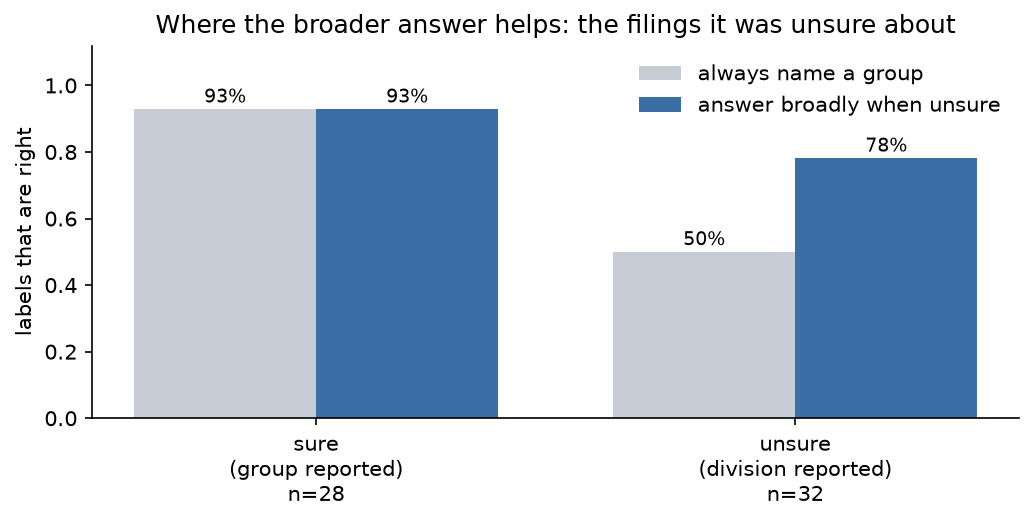

In [ ]:
labels = ["sure\n(group reported)", "unsure\n(division reported)"]
forced_split = [
    sum(r["group"] == f["sic"][:2] for f, r in sure) / len(sure),
    sum(r["group"] == f["sic"][:2] for f, r in unsure) / len(unsure),
]
broad_split = [
    sum(correct(f, r) for f, r in sure) / len(sure),
    sum(correct(f, r) for f, r in unsure) / len(unsure),
]

SPLIT_PALETTES = {
    "light": {"surface": "#ffffff", "ink": "#000000", "forced": "#c8ccd4", "broad": "#3b6ea5"},
    "dark": {"surface": "#0d0a0f", "ink": "#fafafa", "forced": "#5b5f66", "broad": "#7aa7e0"},
}


def draw_split(p: dict) -> plt.Figure:
    ink = {key: p["ink"] for key in ("text.color", "axes.labelcolor", "axes.edgecolor", "xtick.color", "ytick.color")}
    with matplotlib.rc_context(ink):
        fig, ax = plt.subplots(figsize=(7, 3.6), facecolor=p["surface"])
        ax.set_facecolor(p["surface"])
        x = range(len(labels))
        ax.bar(
            [i - 0.19 for i in x],
            forced_split,
            0.38,
            label="always name a group",
            color=p["forced"],
        )
        ax.bar(
            [i + 0.19 for i in x],
            broad_split,
            0.38,
            label="answer broadly when unsure",
            color=p["broad"],
        )
        for i, (a, b) in enumerate(zip(forced_split, broad_split)):
            ax.text(i - 0.19, a + 0.02, f"{a:.0%}", ha="center", fontsize=9)
            ax.text(i + 0.19, b + 0.02, f"{b:.0%}", ha="center", fontsize=9)
        ax.set_xticks(list(x))
        ax.set_xticklabels(
            [f"{lab}\nn={n}" for lab, n in zip(labels, [len(sure), len(unsure)])]
        )
        ax.set_ylabel("labels that are right")
        ax.set_ylim(0, 1.12)
        ax.set_title("Where the broader answer helps: the filings it was unsure about")
        ax.legend(frameon=False, loc="upper right")
        ax.spines[["top", "right"]].set_visible(False)
        fig.tight_layout()
        return fig


# The docs build sets COOKSAFE_RENDER and also draws a dark copy.
for theme in ("light", "dark") if os.environ.get("COOKSAFE_RENDER") else ("light",):
    fig = draw_split(SPLIT_PALETTES[theme])
    display(fig, metadata={"theme": theme})
    plt.close(fig)

## Open it in the playground

This share link holds one filing and the 75-option question, so you can see the
distribution and the confidence it produces without writing any code.

In [ ]:
playground_link = make_playground_link(example["text"], questions())
display(
    Markdown(
        f"🔗 [Open the filing + question in the TypeSafe playground]({playground_link})"
    )
)

🔗 [Open the filing + question in the TypeSafe playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIAkignPgIwB0+AIgKIDKAwgEpEAKaRA8gHL4eAMXwAhAKqMifJoxp8Agq1YLuANXp0mbTt36CRaABKaJUmY0b4FUAE4QAzg+uJbASygBDfELdJPSFBungA2+IwItgBuHggOADT4RIE0bs7eUBC2AA5ZnihuEEj4AO4AFh5lpZ7OAGZZiGD4MEhgkfgoZQj4IZ4lzhC1HV3hKPndg-jMECF5kPhFdAhQZABG7RSJAEwADDsArDTiqG5hALKetlBVWwDM23sA7Ikl3a+23d7lMyEAngC0EBKSAQTQcMFWDjcYGCtl+CyGzE82VItls3l8-kCwTCAHF7DBsolklAqIl6rZXH98ABrJBA4o1ax2RzOBSuDzeVgIUL4egOMakKZZbJUAAUgBwCZgKLiAXAIAJQ0HjFABSARgl3hFB2Dx2z2G3RhHygKCyA0RMrQ+GR2XsUVBiXBqwAVssUB0IAb8AharU3W57SCnAjrfgPgBzNIodEFRYlNydL0RWDuApxa2tPmYa4BcPdaZwOBpKFFRKdbq2z0x7wObJ+QG+kM2ezB9mRTk+PwBIK8iLRWIJJIpfBizHdnHhSIxFYOeUeqaW-AOMqXBBlGZtWzmsPLLJNRYXK5VTb4XZ6haM-CVsP5byrGppGiMPwrBdcQCYBM5VjAoUHnGkd16UgmlNL1K1yBxQWtE0AwTNx00mMdsV7KcBy9aUuHwI03TNLDlmhKCE2qf9inLfB1gFfA-FROJ3UmDCrQCJokJ7MI+2ndMmLfNBPyXFcPnXEJN2cUDa3rQYhhYid2LQ0CiyQNwiwAL0+JB4VyUgTl5SZMiQWoQg8OihmoyJaJoNARmXVdtyklD+xnUpTIWYEoNWeEGJedcsKjdxv2A0NTTGMJJk2AAObV4gAFkeAA2PjrPnMiGPigSN0iAZiiya1VggGB3UPa5T3uU8niVVV1U1Sgtl1fUAgWWxwwCNwlPyQpin8Rpwk8P18CMS4ctsJJEgAGWG5gyXwCkqXhOkGWtZxGG67o+tsAaxB-Pw4mcWgEHtWZskQVBhTgbIAnhSVFp6laBoVTzKio9JfVOYJ-PjRNcsG3oGtolK1zS2xElxWhRAUId7QFQ6UEHUbmESTxww+KDQMrGI2gWbJIlapBw3wLw6yCqjSJGKaQ28WY6smAASLZ9h1PYdnnTJ7UGiAMZjPwcawDGkEghxzIqZxyeKEomTAGAJnKpANThKqHm1GgjCBXbIkSH0-Rg+1BBNCB1kGigYt1UKXgrTxoQRIYyNtF83FOsIuM8KA7HFpoTI+SixYlhYYE+iA6tAy7lv6rKdr21nIeO061Lh9InDccMQRAz0A96oO9ZGsaaAUd0yIcTxEA6RSEGN71UFMl3UE9MnfcZNFczIZB3TeqoAHUfrOXLUFN4oOHcRB0-Gu7CoA7rame8Ymibr3Bp7uICNQRIzlsGgAGkQjIBwlJoVvyKyexXiaSmKFuar6cm+xyFbyj25aMY-HwHvC-7+cUYI9HMYKbHceRBNeVApn2lZu-Dm3pMDc15vzACQsHrelRsgFYTQ3IZmaDzZY3soKViLE4LI8J6RCjFGRCUfAICkAVKUCoQ9nD0hKFhcWWtTS60oAbEqOwACciQWhr2DLpZmwFM4hDCFbbEtsMzlxopRB2Tt0w31OF6IhQoAIe3qrjIoPDQT80+NkbIBkvCrDXoTMR7oYyezInI7oAEKBbAAKRXnaAEKW5AsArBRITL0ysjqdHyI5Sapswh-xUZEd0Z0rxZFjJlC2IxBFBGEVxU68IyKux+oou+5R7peEgl6G02jPC6O6EYi8sjiHdCsvwg0HxuqonIt0CgoVrFswzPYzOgS1IF3zlbLKoEyKKLAOMEMJjClwxKblKGYxWjAMiTbXkLRNwFKFHATwvw4bZ0sjMCYKI2q9JGIrISKtKnKKQKo0RnoPrKMLIsKybtvQAEcNS+M9GRIZAomJjPcEI3kecO5GS9Lgw0sE2gIPhFQLYWwaD-HwLcfAoKOCsB4BwHgjB6C0EEBwegKg9B8CsNvVcoY2ihwOg3JcYw8wnMjr8JU3s8K4vDo8ol6xGrCy6MLDRKMoLHO-L+LaV5eiZWKEQ+0cAGFsOYTFMlg0tF1RFiJSuJp5qhjgCExqNL7A0naBSE5rhWI7l5LRHp0YAi5xgkUPmggeUQD5Qwig+ozxGy8Q3Mu+jK7FAUAjBA9cjqTDOJEPMg0uIcC5SGbkWQ6XNVanGBMVQZTQrEIUe+-E5krDypyMI0wch5FCSOCNPB5RwyvO4KIPTpizHRPMTIKb2aljIaZRBxzvj8IBAyKCTooQwk1IkZsrIXDti8Mya5aQ4KLGTaKF4uUhL4FcESyeGaXhhusFCnglTgE529jEGIn8G4JlJTOyNJRh0gQZZUzI+dq2CT+ICFyYIIRNthBu8QuRihQFmL+HGZEx07NeKUHdD1wSfA9ATEKRtqlsMijFLYv1JVegzb9QSwkXGOJXNjboqrQjBXCQgNwet-2hUA8Bz9zsRFe2GU8z+5y4hlVDLUGAtbEgwhCHlVyD5BxkQg8RqD6V30Uf3MCAKxDtJDF2PECgQH4gsOw8R7cBYSXHTlcURgpooA0kzukHc4IQifM6ABXVPMHahOLtu9j+AVya28IFHj1pNH2EwIpcY1I7ijtOAZM5-EEKIggKc6TsmaQ4aglxB5IyYTYyOLer097HDAMmM+z1Oz7lPRWFuPD2FtaxcmBB3TI71gHomOSiSsRYtcXi6aLcIqlwrPNtluLaGcIA3wIvFea84AbyHXpt2cdihq39IZpZ3QCiHqGMFx96iTmrE2k0A9EmUv7jZj0qZ7QyIdW6AoJSpBCqiEKA4IIcCi5DlJIkLKDgXOGnbHmtN5YPiDH6710L4T1Pok0wa4oAEnSumlX-AJXc9kfzzNiOI0dR1ZAQxR6kMJVs-kguXcDzrXWfI9d9b1mZfUUyGAGhqTUWrabw2RD4PaPjh0mJ4GAMJ-KjyxBqx5pBIZ1HPpungAyig40nmRG0doTNkQ0-qtNiCc6OZY4loYEGuJJRcySzOs7oFkW0cgSCEwhijzXggvK+BcH4F+Agd0xZcOnU0lDQC49GYC5C2myYcyUAVK4ogToEB9xDB-Ah9pZT3vkS0+2Xkfh1ZppfDRvzON7wmkdwIkE8AijBDLBCSIsAH3D0zAETo6JMCExd21I1EGVzpBCLtnosQUFNDqlgKMYzxhHVVcz232OhgxHRGEZ3-pFhu7x8AowRA1DEj0jR5ALU8MaTXUhuJIwJSDdsE0fSMBZT4FLz+IXkaxU83nA7THqkmg4oQPtEBOfP5cXpHtUp390wePdF4YocrNZR9yuGKo96-CJo6O4UIzge1yb+I6Lo2Quh94XV0cgh+YDH69EIWgoMGemt5JWDOLzHhp4GAHmtiJ-OWG-mUASJ-geuqjiMGqEjQGcEoMvPQGgBip8B8LjN7B8KgNSPULACDvkqBFpjKt4HKrYCgAqt0KsEqiqllPASHhOGUmENqkKCzlpvHqUNOt+KcGAP8KaP8OCERI+noqdGAI6HMiUjlDHh8LfAIvYI9prqqv4KEm8pmBGG1LyAoT4qxu-sfkMl6McAmFBDJuMEamgJ6N0qQMXAZt0CuE0PSNBAUJrIAmWjzDQLQN7MAlalPASkYuGPCPGCUkQT+PkvPvtMAt4JWCoVeDbAvptDQCoM3FVqoCikQAoMNFYBZN0FbiGOiNQobj7v+JQsQrKuMJfmELUFpllHfMch4SGpPp4pbG7Pil1ggFvIaJ6ArlzG6DeMUVUTiGBusJUaiBOLUQli4mRORigGgjQMwJIGgDwGcCilYAoHwIiswKscitwGioIOSmyptMGBPoTFEDMODK4TEYplQTQfDHQQwYNKqswVcKwTyOwSTp1tdqzvHhAl+BtH+NAhUMftSCNsrnBPaOojgVivYpELlM4FCEWF9MSk1OmC-B7kuDAIVJBPZOmHfGRKYf5BYaQNuG2O4F4IVuCQUPls4KEWEA4fgM6lUZNF2MhGEG7B9A5Cbr9iAmzAUOkgSQLORICVtIVtks9CgHEjYcrIvscncbQeRE8Q8SKeysGPSXhNzPuJlOShKQZFKfOOCI7FtORrWqOpcMqnROSriRxCRMMABCCWUGCQLhCW4d0MgKXkUJDIsXgQ3Hfl4oyS4cQaaK4HUFlMcjaQON0V-EgAruGNLJHi6sMJ4m+hqWMdknoqBPMKnkaUAaaX8DQCDMwMvMNDwLiNYO6DtCsPyu0LcCeFavYaAfLp6F7jSLMOGEaqCpFBCnyGcBwKWQAJr0BMD4DbyBmehkBaIQBK4ITHbJnFDVb4CrzrxKTbbkozxNr4pcTJh6Fwj-BoBlLggfBLy9QVhcpgY4qFI9AcoeLFD7DWKTDCmdHzisqilODRlnGgQfCKTfhbgZaDRYCoJulhneolIghAGVRcTBkuaVTHFAkfBARQT9EoJGo8DkqIA1ksxDBzL+B5jhzfDWgp6eg2kIREzdCiC+x947grABjpguGgH446FhDgmaZpqIZG7ICYkUWXBNCIAQnYxGqzpQpEAYFKADlJB8BCA8CsCoEHHbxzQuHgTuDK6VTO4NDNE0C4g8AaCsB8BrF8BWisD0C4jiDDSqC8ACDPiBBvASzUjkFCndB4wOzrqkxKkQDKqVZvrzB9GgIDHhimqRBIDhwRgUbNEDCfR9BgaMlBIlHVFUQnTkGLCj74BGXwpKDMBGDWBbFaAaClkcD6VWhjmeCawgjMxLjcxNLwjvI3wuLtGXCFS5aylhxbkaxwQkZ8h8BqBEDQp6X0AGXZFTC7HDRZF8DMCaBWWvhvpFB2XSoOVfynRBAGk45uUeXFzeUVH9HSoeloZekNy8i9D9DzjRXNKxUTiKQLV0TFDJVGA8BpErGCCiBoAKDSCCDiCsDhD0DMA+BEDDV8C4hYGsl6J2I3KJDXKXCoj+lcS1j4S6EIC5DUGDiViYDwhfFk5wyZjEJP6x7qVpp04jDJi+FpjOD0DZhwZEoFiYIljFBijwrMCKgpVw0hKI3mYo2CgQ7pAY1zlqWUjNGA1QR43dC00xm7J+DQ3e6Z6ZiZB1heYdZXgQjaI7h+j4GvhTGSnwTbhkRC2eLagMwiAyaIzuh8BUD0ATTNw1AVDYymhICJC0BfW7D7CRQsJPjYlVCnW8hzJVVEW7ISJbRIVrwmj2AKReBmmIKIB6obKC2fUADkdJCAkIZh1ojcJQJQVAkEpI-lUQhWfg4M+WWuoSzgbQp01B4cu+uyukYw4tidAR4ywigFsAbpJWr4swXg-knixyNdPGo8r4Fi4KRC1BVQBaa8RKCggYtCjAMACdZ4iQQgISwo-CotiQBacwnooUBwWwkUhWj+RQ3Q9iDCbd5KXQoBYN1BrGAEYoLCjwOwc4+wtwOw-wOwx8hwo5jlvpBB8I45jk8dpAT44gog8KAAiuIH1VaPQBoAZcavgLymsBsJansNam+rah8Ickgk6ojMXlVhFjDk0HDmEgzYGsjrzROsLstp6BwLGg7AgAmsHcKKWrzWKBmlmqGFbIdvmDMMvcorQ6juUJWvCEej8HWmelifHc2nCK2iyK2ByF2jYD2lCGmgOhNGNqOhFrwYmJOio+GsLusC-kUkurBKuicFKWPnOoo+WMUGlntgETWievWuesI1egFosOdpASMC+p5W8B+qrt+sZshpQBhlhiBqJolCMExpzv9HabBnXJNFlEhhHWhr4-xphlFNhp4xLfuHlI8qMkRo5qhZePmQst5DRv5PeFCAxsE8LsxmE2xiOnNEZtxj43xgJgbMJgE9kyGOJkEhTYsDJtAPJtYIpm7BRqpk+T8dweWqmR+tFT+iZn-hZiUdZuCsifZsUIE-RC5lJqMD055qk-hhkx7v1qgy6tju4JGP4GaRiUjCuCro3B+qiPJD0osEIHHbYNLFqPWXsCwlREMN4MwGHp-E4c2XRI7L6WANGYg4RBXEgnnJxVBAcxDvOFgJpLup1pEHc2mrYZ1p6AVMeG86wi4mKq+GFiMOiyGI8-QS85QDi07RA1ixS7qIKgg6XEg-aqGGnUUJnodH8tYODuHKBAi5xV6Lc12Gizqpi-VVUHWXS3i70ASyhlhPc0MDSxQJSzQMkIRcFHOW7BjCaKU3Nty-iu6pg3hjg-6ggPgwpCjusljl3HafmVE1cLPt6L6G6CCvgPsBCiAIkCABgiiA4BgNgHgIQMAAADogAIy5TZAhsEDBsgBSkYyRv4AhvXAQCxAhuJAhui3RjYn53xshvNzkJVD0G+zlxiwCgyyQBb7CkjZBJNHyJIAAD8+AKoeORKZEVbakMdzkmUE2+dMqamdQz0n8bQq2vkFbZAVAqbCbIAdgZhl+8b0bOwFAObIA8MFJgz3sAB9gYst2-wLI2QDgE7IbOwWwS7K7Hga7ZeOa5u-wBkOdmzAAZBmJZmEGLTiETQeyAHqCewjGeypuu8+6hDOO+zsKFEuxSLRHCEBywqB2kBbeGIkGUNIivpmLqpohzO+9qEu6bu7Wfp-IACgEhM96eOcQBA-lI6UNpwZVv2DgAA3LZqtgvlyqaxEVh8FG7Oh8ewGyG4NvMfJAicoryA+wZPHAnfJBzLR9x-AH4Hx5kAJ2nsJ0KEeVMd0KJ9jOh7cEu07GjBjNGCsvAPgA++oX+0yTULR2AO4PPZ-Mm2EA+41LHfwjRwsDIjZ0yKPAvk0FzIWrzZGTOLR1Z-p8Z-2250uAB19vLssOh5FJhzhzjA+8fXCBds2UFSpfPVALZiCGXs4GKC4eRgvrOOh-sEux9pjGELomADjOXeiAls4KCk1m0FpCV0JB2b5927RSKQIelLR0Vxe6V+V0ULqlVz2fSEgLVx3g12V-ux65O-rEu4fVEPCLpKW1m+spjdNnBuRI13spRKChV3UbFvh9XkOwQCLKiI6AgO8IkHWBjAZCCIkPAf57kO8GniCJt5m7duh48Bp4aq92mqCi+7-EWo5X15V7SfgPt4EO7sR96P7dGOfturYDSO+7sKBxAObnhjSH4GZ+gpu1m84GD4R4d0o54gtej5-BPlDLR7nD+A8c4A+yt6Kh8EXVBGHe6JWFu+T8EoMzLA4L0B-mUBMUh00IAVtGJ3K2hupNj9q7R7ELjGUuQA+7UPYCpMUEO7iez7vgnOSIr8gPd+0dEP3s8wmIkPaDF1E6j39ypurbR+rw6GfBPVDEbwgHBzmnEFOKF86HnDT-gK6PPXEJ1+iHfIs5e2zxN2myAFsIu5xzGzrBIp6Kzzj6DwRxDw4AQEEI1AoaSYjxxwQCG6QNgKcMp3ZkH-H3j0nwQIW6AduoGN4vQR4LZvZ7d8QlbeJ-YBXwFcULUTX6l4s4ODheaWjKPAwg+1CCEDSLR3SAmHbt32PwpFaaiK8JcHXynlb5cNp5788x2Yj+p5HzaKuNZwsHOYTjB4L5u9uB3xSZ70iacAv4bmECX0R8n0o0gB2w+zlL8A4FHZNN7ApMuB2UOvD7jLME6BO8H2SGeCE0DT5k5aO26Q6DHUSCU04gUddGk0GdAtBCgiWWjLYHn62AoBe2J-j32LAIDbuFQISPgWf6x5I87-ZBJuAgENwHOmCFYPwgCBMc6g2SCktrlz4FAJCEvKGIj0i6R8aMmFfztulR5x9tWI4bLl-wTBoI5wd-AnrnBKDd97uXKSfnZkHBddQgtHRZsIKkLD5kALqSrFol+DaDEgQ-b7kZ20FKNMKdAnWPn30x7YHOtoH0KwM5CvQUeCCRrp7xGzb1UAIfSdjTBm4Ik-oI6cjLYBn5oIcBqPdcFbigyf9QhUgj4IkCy6ehCQgkAUGXHlC+dosf2OIfMQ+CZCu62QsITgSSHvpzcGQuWrolr49d-OCFbXCEKKEIBaORdGkvHnvwL4ogTvZuh5UHC08sh-nAULyVHjYA0EdAtIAwMY58d6h8Q7oPLzcDDC2Ok3ENlsBihLtTobMT3qAKx7m5i+ife-gQGyAUZsgi-BwciHaBT8rwpw1aJRV4qqCmhlwnKDxTexdxWML-CAJgF957IDkFwupA+zWGRAHhVFVnplyDJ9cmBW4AAPRyE4g5QsVAKA8CDh6gTnfjv5D+GDR7wG-RYWHw+6R8QQ-QVEQ-wOGVDlwoWUVPLRg7AJfhLyd7E0PbDm5E0BIskcSMs6kiiRsHHXtRBF45R3KDI1kSSIqEGQmRJvQRNSJ3juUc0HI7GJoLGEMcmBfHQkQKNg5W81mLBDdhKPDCaCmo9QVLG+RAp1Y-eLqO3F4D7y+ClhIHSPtcDID0j-Omw4-tsLEGyDIeGPH8DDydz0gkcQdXGK-npFNDegcIrvsMVCCOhfgqAKoE1iQDgjnmqwXWLdwY4UZHA4gz0OGF9GzgfRNQAoP6ImJX4gxIYpTKLX85DcogFGUugvjTF7Ytwmg0EB4C7DMUvRwdT3jlBGTn5RB7PR-JcDjSUN0xG7OGpcDCpS9igMQHTv5zvjLobCwQeOI4HTFCMMmPnciIUHbJNjuBg4EoYDnHF+ipxIyGcOUN2zIgqMyuCLD4Nu5rxcwzvIumFQu6RByMiAQcJkAcCm54RiPKDpH2072A14enD4If0lHzRWxKmC4SuhN72BBgwCN2kvzo7jDZRERZsduGfG6c5e-HEIO+1vpLsCgFyB9n4HS4dBg8DnSMYP05Rpj4RpvFAFgM641BLSiNB2DSBN6QRQgOMHFGhAfbYT2gvw30emOcDrhIItHM-i4KggMT6edo+3mFygBSj6OjAkEHKOYn4TIJtHFoOCE0QhJ0E4kqAP2xCCwTlwBo1MX6LDJ5wi+kvXCRpO0n8TwKCEiPtnxABHi5ygnHkHOUgkJ8DukPeoMQiwGJCXCPE+UAhKz6Tt9IniJMTUAc7eTgwNnZMSLASHO8nALKNEbMGBCddkxTwzaOWKZLRTIJcA0ApLjlpHgagUEPyQ52rINx4OvwMzrjm0QU8zBF7e9PMn0kODG+kQeEPRJLEojFxSowIAoQ2zBE92enJiWmPaCQSEJW-EyWkIXzvp4eg4XRGmNiH+AHI9En4BSNZLf82R5wvqWEDh40ghpzE0aRQzX6TTP4igsUJkGVQLBAwKYglC6gESJF-O8xCiFL0Dr9DSA-U+oFMmUoODe4lUW8Qvjtw1SPxOMSYENyVoEhnALHB6ZZhljNjluXzAQX4HgAU9dwrQJ6YgAt6fw3p0XEMF9MiA-SlGQULCRtJolFEppCLZ5piU+lFBvpfHP6QhL4EmSWOMZOgclz4g2w6wn8e8GiFy5UZnmdWRIMqg7L3cfEWUvKGvFEb6YmIpoGYJ73UEMkeKQUxofpksnAIEAPaIkCAicTugF8ywIQW2OtBoZaOTE+AINk-hDDchHww+nbmlkT08U88OWXDQVnQ8KSysykKrOeJf81pHE5wS3QbTFT3aVMySajN5CQAzQjoc2pryhY98NwHMT3jDzgAOzO+2uMVEKEWkjgco+fQaMuFZh5dMRtwArpH2QAnN0wD7XIVrI+G1FrZcaC2lVP86GybYkMWjgdWKDOc+82vfriDwfbrh84Fc-zmnzq7OAS52QBqYt1uxwCEZD7YCaxKYjXccYBc2KdVKuRGzO533dZCPPS5jz25UohSJtIdiFyZYD7duQmMc579bOrJILgXOLkyzyhfnZzoFxHQzyi5a8mWWXMJglsXRviZ5nJgYzA9vZF+HxLhFMHkT0oCElYWnItkB5UutPOcorIDrn5254cEoSNgwHjybYMg3YQTwe47JAcMPPyOsiH5atX2cSH4lNA65Lg3o1wPMAvyH64KygAIzPJoh7HzEHOQCmHtQydGlsJwO-GMD+E0HEI35TJPQTGDNC0cohkEGIZkmCDWVKFFs2vtwrO4JR5eeqWjlQstlCc+eU0+MC8k5iXyG4XCwIbwpryegH2sCCckotQAITsRZMlhYNHtDkJOEHM0KfBkGhGid4MID4a9w8wv8IiOUGxdYNzrGKPAEhcGhsONJYJ7ptHOxS-LjkuKsoDcj4abCuDohag7oX4Z4to5hK7A5SWJWhniWRKS4Gcz3unM2gXCEaCEs0b1J5BHhdxi2VHP4DzSNRUc8ZaEN2A2yeB4S-gKhryAcBv9y52SVNNglMyniKF-nKYbrNiV5RPQFXQWXax3DxkgIwCEbvV387wF2C+yHaklx8F9ib5cVDNszNoFDKw6R5CHFRjSBip8mUFIHjMD8V1NmowCAfGbFNwvDlEiHGibtAHB9jFuZONZTyGDm0QEuUiqsQaTXn+0lwzWK-M0oGj5A2lAQUIL8E7Hl4eYmbSAejFBWEx7lqyiyShQQmPiTJroV4CEF5nD9mYYspQdrjFm0cUVC+XmY4KCBEzkumgjaDQvBUrL5lWEH4Bf3mJOtE4TS4zleLLDTlPBxAzHngN0EmL0wy42lf50GxQBfg96aERT3hqvTE6TpCEql38rm5Bw4FGkTzHPHYgU8-nOntaGoJRhKB-cpUQKHgDdB8VaKseWvhenq132kUHYEu395oqi2g4a7ggH+ArgKMb8dmJ+OtUt8wQRCqaYK1ObehHkrIsnOauMmTtm6snJ0N7HvCkQfiREVCYywjV1QygJQdSD5PTnTYfi5q9yTn3vkk8TemQXwu0G868r6KaGcoXYuAQlDQ1IQGEWSNS5izuFU0gYeiDzB+KUW1Y80iZCJwIZnK+pdWmssMVnxUMx+bOD8XFXmrSZk7Y7mmr1TireaDoh-m0DhrBdvAYHZrC-J5gzr9cUub8kOvNWpyTJYStdbWBCTNFHQFosWDLkSWWKPo8EeOSFwc4HqWcG6tqIkCG6rYug560EJevFUIi-gJy+CEJA2FoZxVHQVtb6sLUmiQAQGVYSdPtXAjei+QIzrZ1cmYjooSEkdcerTTgabJ4PPYRquux4V9WFsdDdQV5qTAFeg6vnpMsuD+VzVuSydkWkKCkA14W9Z7vAVQEt148La5jeuFY1rN2NYVDeQxsKTcbt6paxWQjGRBVAAFWNK8bnCJRsag6vYm8DCBbIeq0kduEnJxpA1rwYgVNNyqAXU3AJNNhqZfjkjVVWSypTGm5XpvA1KjCw-GntuBpfXhcUNSKydm8qgCJBt5Q-JqGMC553rsN+PSHh5uC54kHOhnC9tvJZyU02otHCLbyCi0-FMEaQRYA+0QW+QE0RQOLQhsi2iwfIbgZBVlqh5uhLZ0mgtQFoPQ5ywAxEz3uqqw2VahsUAlkjJMMEU9fNT0u9e+1phLsa0cQUIA6rFjogzNsqsALj1gWQ9etucNeP8DlSuK1w7izOT9jm08qslmuIfoSC0SW8yEKyKbQ6tm1ZQ3FIqrEpogMiLbcRq2hzpNv63-BulaCfziEtGnkiBKUAwSH1um0CCcJ6qhblPMWA6rttnCa7R9p2SGDjBi-aOQ+wsGRxcuL2nbddsrB+hY4RQWTq8Q1SgL8U62k7Vtqu3TaIFqIT3mzBthP4tUOiqJUVkiW4r-tb2vbZWODq7jO4e-NifjGJ1Gzw4GOzbXEC63BqQ22Oh1aiI5l1J3ZPO-4GZw-zM1WYylPzb2rS3r9IwAoSgeCFaC+LKdu2-4AwoXwXd4Ir4EbZ71wRaahdYbGLFLrzpbDg+MOgHdNoN3thQuwsp7uLKF15zyAzYwYuaUzEgShdFoosHWOtE+9bRpu5XXDuVwvjKG5Ab8CPwJQCas5oGq-F1szUgA9Cpwf4PwSEhASAxKeeDqLNXBeaeK2vFrdSDnUEB49IQa9prMYn78saSezEv3Lwj9a4phembTYL0QPa2gNeiDTfStUqUE9hdcGlSnywfC69eaCXazSo60c699Athel1dlpTRk6SRtRzsxEO129ihG7W4IJRUdAtpfHcEvst1c9e9WEjvUXu4TIB4I1lVfQsND77A919G-farr6XV6eZQsmoDMEyXGbJ8+ezfT4hv2gR65FjXPUPrP2Tt9g38kyXXrV178faPiv-emDf117oByADtsFjUxEZd9I+6-bUWRLzdABbI2fXvqX0Jyiku+rrfoqv1L6Htt24KVMMFHpKSdp+qA+Nof516yD+B4fe-oT1CaywUQSZYan1UAVf5QdREsgZYMH6BckCh9rjoLWDBCJWKbAygaX3Gg9wOvUyCWk5ZjAMYNB1vXRpDZ17JZcMrCC8hzW4SZxWhrGDjHxZz7z9bmzQ9fvoEyjRJERQvevtw116RdOMbA23nsBWwVKO+5g6PulEiTmBfEVmLTJxja61DMhj-Yaq8NuwwjCe9cFGPyamgx5jUfOAnL3bRGi9r63vYIewV16W6oQCACbzmQJ69w7QERTgY-32HsDzmqAO+xiiWqcRzRXkCjonCRqlpRUnpE0d5AtGspyot4p0YCBLSqjbWv8SRDhHzFUcfoTcJ3k9Hg0y4QxoOTCppKZalVALSaKCGK5gl+INEarZ-0CA9tah-kLMozVkZtKWjHMKozUa50gAJjxXLpWsbLwnoj1PMX7MNiQZEQHin2BwelCR3MVXjKucFVIPzoU91w1BIQii1VInFnAdgSsX8dGNLHRhwkiYY4p1Ey9oTCxgE7Fp+zUFFSLRi5VAhLSas2WtA8udXBWrYLCcVS68j4vvWhSUAiej+WCFQSpgzVmI4DEuzTqE0x58BOkQaULbdDdxLe1WKTTrgX8Atb+9k6mHhC8n0o-J+-V0sAG8022W2rk-jnm5A8tMX4J4p72b336+xOdcOKAQ4g1GepIatwD1FFrrtrKsSx2HPFJ2H0VMVQc09dhWAqKxIBMPuTToaUhdcJPMDieViSkvIZhX8cEKEANKOmqlFPNBKGZ5gWnnTBcFAHojDOWmYVMZxypcGUpbhzjLJ8dem2jNOnPgH2fiVKdixD8QuNRy-ZYa1RfEHDBPNgn6rZouqAVsWZcU1XWFzgLJVJ5ru-Fwj4zhus8OrgUE6MT1k9z2hsyDxxzNDw4FeoOeXK2jdmhgtZ8CAEnyYKrNUnxes+8bW3mlcKrGMUKqjp4HTazHBfbC3pHAF4ugcTGpo7A+TlCuUtjGELAmLMUoF8HhODbjHrgTFoRNRog1xy5QeYLRD83zjInsC-AQzGC5KXFPVz6sXIj5zhLtjinyQbjwF0Cy-OEgoHKz9Z7OrRB5bPM5dup2iM-MMmYjL6AQpjYOAAnyQcYpR27nnD3bmasaswMrmMmla0HbJD-dcKRf86zbcu77R4LHvA3-B1h3x0LbaR4vGmQ2-Fg0wEl7SfiJLYBKS4+mtAfY1sDnfiwt24Mon8cO4cVWceUT8JK8jIJS1tv4uFGh5iQBntwOfVqoVRdsagvd3Yv5H0Qj+X4BDLC3C7ys0qEy9aDkuaqFLtm4SwOCEI2FUVQ82rXOSnMjnjLvhxE23OoP4E3T15B8DJbvX-A0dR0OK7JyPGPpMzofR4OWZAASW+ls21rgzzCWncwtHM+HsAjFPJXccX5Panv0yvlqXCZnWiluGQ05WgDk7SKwifAnOASrcTcDTxY0P5XkrRVxYHWBNB3bNFBEO5KcP0kYmJLPu+cGNeKATXdZ81orcZeITrI1rU14fDNY6BzX0tBWpYy5dtKq6lrckba+NcMh3bjrhWpAGdYCsrWEik1nAuWCqIqXkrWiw66ofSvwSiLFhka65bzhW5Wd1FW3Osiw3VXXLlXHSwdwXSVcPMNbBa6Naiu9XrQcAMG+johuSzNro16BluAqBHCj1CNGocsEhuOMaMkId9qvTZPJW7TiYaG3QYID8Wss40gAWfkUkhhIAA3A3DTs2hPWZw-wKWFuCmmCXfVRortUEB7UfD+LDgdHnpecLewFLUt7xDLbapfXXLjOn+CBP4s27Gg5+dbQ1HPw620Zgx-y8LcNvUNeg-y-LEZYZsWNGbJ+KQ3eqFtxAZtYwiWSGak1qswBlt0LoRdD7hR6brloep6bC202+LyV0ENiQaP-tI7mI0KGJeBvnXdsxOUUyzYDsOAd2HKuVvN1duJ3g7nV8SwTasHE36oQaC1oalpvfnU7AVjJSCHbDYw4YV5q5WZZd5iskp258ODDfOuN39BRmt29nZ3Y9GNUTlqENQxf5zj8j5+OqkeHds53SSduW260qV3GWgVBGo6H5Y3s938Ual2GS4eHv8XVastxEhttno4UHiVKTrUneGtQs2ByvI4z-BljGhUMPrDib9lXUZ1AqgapO0Dflt3rsrk7C+ku1djqEmK1oX0GEog0sIgbQ3QEC11XT+qFRf9gAL4YPJuy7OsGoHShtQA2IAKIBQBABoOgAA)